# SEN12FLOOD - EDA

References and resources
* https://www.int-arch-photogramm-remote-sens-spatial-inf-sci.net/XLIII-B2-2020/1343/2020/isprs-archives-XLIII-B2-2020-1343-2020.pdf
* https://arxiv.org/pdf/2006.10027v1.pdf#page=2

## Imports

In [1]:
%pip install rioxarray --quiet --no-cache-dir

from pathlib import Path
import json

import numpy as np
import xarray as xr
import rioxarray as xrio

import matplotlib.pyplot as plt

from shapely.geometry import shape
import pandas as pd
import geopandas as gpd


# imports required for the LeeFilter (Sentinel 1)
from scipy.ndimage import variance
from scipy.ndimage import uniform_filter


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-cv 0.8.2 requires keras-core, which is not installed.
keras-nlp 0.8.2 requires keras-core, which is not installed.
tensorflow-decision-forests 1.8.1 requires wurlitzer, which is not installed.
google-cloud-bigquery 2.34.4 requires packaging<22.0dev,>=14.3, but you have packaging 24.0 which is incompatible.
jupyterlab 4.1.5 requires jupyter-lsp>=2.0.0, but you have jupyter-lsp 1.5.1 which is incompatible.
jupyterlab-lsp 5.1.0 requires jupyter-lsp>=2.0.0, but you have jupyter-lsp 1.5.1 which is incompatible.
libpysal 4.9.2 requires shapely>=2.0.1, but you have shapely 1.8.5.post1 which is incompatible.
momepy 0.7.0 requires shapely>=2, but you have shapely 1.8.5.post1 which is incompatible.
osmnx 1.9.2 requires shapely>=2.0, but you have shapely 1.8.5.post1 which is incompatible.
spopt 0.6.0 requires shapely>=

# Files Structure

In [2]:
# Let's take a look at the files and folders in the ROOT dir
root = Path('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/')
files = [f for f in root.iterdir() if not f.is_dir()]
folders = [f for f in root.iterdir() if f.is_dir()]
files, folders[:5]

([PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/S2list.json'),
  PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/S1list.json'),
  PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/new.tif'),
  PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/.directory'),
  PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/new.tif.aux.xml')],
 [PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0111'),
  PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/7'),
  PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0105'),
  PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0217'),
  PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/47')])

In [3]:
# Let' s open the s2list.json and the s1list.json files
s2json = json.load(files[0].open())
s1json = json.load(files[1].open())

# and grab the first item
s2key, s2item = next(iter(s2json.items()))
s1key, s1item = next(iter(s1json.items()))
s2key, s1key

('0063', '0063')

In [4]:
# they refer to the same item (folder 0063), so let's comapare their contents
s2item

{'1': {'date': '2019-02-04',
  'FLOODING': False,
  'FULL-DATA-COVERAGE': True,
  'filename': 'S2_2019-02-04'},
 'count': 1,
 'folder': '0063',
 'geo': {'type': 'Polygon',
  'coordinates': [[[28.29722, -15.382762],
    [28.297507, -15.429039],
    [28.345216, -15.428755],
    [28.344918, -15.382479],
    [28.29722, -15.382762]]]}}

In [5]:
s1item

{'count': 2,
 '2': {'date': '2019-02-09',
  'FLOODING': False,
  'orbit': 'ASCENDING',
  'filename': 'S1B_IW_GRDH_1SDV_20190209T163240_20190209T163305_014871_01BC1F_7E74'},
 '1': {'date': '2019-01-28',
  'FLOODING': False,
  'orbit': 'ASCENDING',
  'filename': 'S1B_IW_GRDH_1SDV_20190128T163241_20190128T163306_014696_01B65E_5615'},
 'folder': '0063',
 'geo': {'type': 'Polygon',
  'coordinates': [[[28.29722, -15.382762],
    [28.297507, -15.429039],
    [28.345216, -15.428755],
    [28.344918, -15.382479],
    [28.29722, -15.382762]]]},
 'urls': ['https://datapool.asf.alaska.edu/GRD_HD/SB/S1B_IW_GRDH_1SDV_20190209T163240_20190209T163305_014871_01BC1F_7E74.zip',
  'https://datapool.asf.alaska.edu/GRD_HD/SB/S1B_IW_GRDH_1SDV_20190128T163241_20190128T163306_014696_01B65E_5615.zip']}

In this metadata we have the acquire date, the folder and the polygon in WGS84 with the patch footprint.  In the s1json file we have `count=2`, indicating there are two images covering this area. Their names and acquision dates are indicated.

Let's have a look inside this folder.

In [6]:
folder = root/s2key
list(folder.iterdir())

[PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0063/S2_2019-02-04_B01.tif'),
 PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0063/S2_2019-02-04_B07.tif'),
 PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0063/S1B_IW_GRDH_1SDV_20190209T163240_20190209T163305_014871_01BC1F_7E74_corrected_VH.tif'),
 PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0063/S1B_IW_GRDH_1SDV_20190128T163241_20190128T163306_014696_01B65E_5615_corrected_VH.tif'),
 PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0063/S2_2019-02-04_B12.tif'),
 PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0063/S2_2019-02-04_B04.tif'),
 PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0063/S2_2019-02-04_B11.tif'),
 PosixPath('/kaggle/input/sen12flood-flood-detection-dataset/SEN12FLOOD/0063/S2_2019-02-04_B09.tif'),
 PosixPath('/kaggle/input/sen12flood-flood-detection-datas

* For the S2 we have all spactral bands from B01 (Aerosol) to B12 (SWIR)
* whilst for S1 we have the two indicated images with VV and VH polarizations, and the values correspond to the backscatter

In this folder we still have a final file called `infosS2.json`. Let's take a look at it. 

In [7]:
json.load(list(folder.glob("infosS2.json"))[0].open())

{'count': 1,
 '1': {'date': '2019-02-04', 'FULL-DATA-COVERAGE': True, 'FLOODING': False},
 'geo': {'type': 'Polygon',
  'coordinates': [[[28.29722, -15.382762],
    [28.297507, -15.429039],
    [28.345216, -15.428755],
    [28.344918, -15.382479],
    [28.29722, -15.382762]]]}}

That's basically the same info as before.

# Data Visualization - Load function

In this section, we are going to visualize the patches in the first folder we just digged in.

In [8]:
# First, let's create a function to load the desired bands into an xarray Dataset
def load_img(folder, filename, bands=['B04', 'B03', 'B02']):

    # get the files paths
    files = [folder/(filename+f'_{b}.tif') for b in bands]
    
    # Open each file with rioxarray and save them to a dictionary
    # using the band as key
    files_dict = {b: xrio.open_rasterio(f).squeeze() for b, f in zip(bands, files)}
    
    # put the files into a dataset
    ds = xr.Dataset(files_dict)
    
    # convert to an DataArray creating a band dimension
    return ds.to_array(dim='band')
    

# Data Viz - Sentinel 2

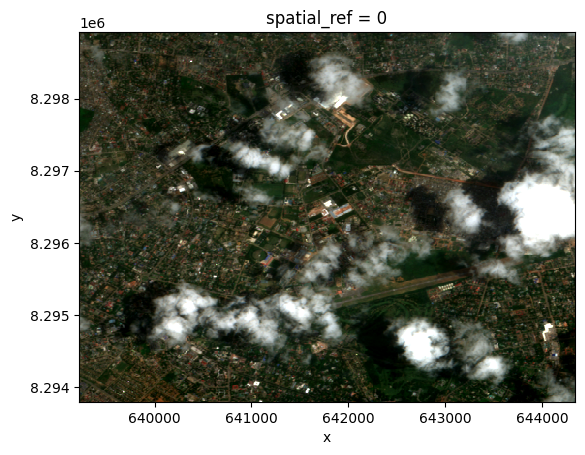

In [9]:
s2 = load_img (
    folder = root/s2item['folder'],
    filename=s2item['1']['filename']
)

s2.plot.imshow(rgb='band', robust=True)

# Data Viz - Sentinel 1

For the Sentinel 1 patch, the visualization process is a little more tricky. We first have to remove some of the noise (using Lee Filter) and then create a false RGB. Let's declare these two functions:

In [10]:
import warnings

# Filter out the specific RuntimeWarning
warnings.filterwarnings("ignore", message="invalid value encountered in log", category=RuntimeWarning)

def lee_filter(da: xr.DataArray, size: int):
    """
    Apply lee filter to a DataArray specified window size.
    Adapted from https://stackoverflow.com/questions/39785970/speckle-lee-filter-in-python

    """
    # get the kernel, considering the number of bands

    if "band" in da.dims:
        da = da.transpose("band", "y", "x")
        kernel = (1, size, size)
    else:
        kernel = (size, size)

    # create a mask
    mask = np.isnan(da.values)

    img = np.nan_to_num(da.values, nan=np.nanmean(da.values))

    img_mean = uniform_filter(img, kernel)
    img_sqr_mean = uniform_filter(img**2, kernel)
    img_variance = img_sqr_mean - img_mean**2

    overall_variance = variance(img)

    img_weights = img_variance / (img_variance + overall_variance)
    img_output = img_mean + img_weights * (img - img_mean)

    # write the mask
    img_output[mask] = np.nan

    return img_output


def false_color(vv, vh):
    """
    Receives a VV and VH arrays and returns a 3D RGB array, with a `color_band` as dimension
    https://custom-scripts.sentinel-hub.com/custom-scripts/sentinel-1/sar_false_color_visualization/
    """

    c1 = 10e-4
    c2 = 0.01
    c3 = 0.02
    c4 = 0.03
    c5 = 0.045
    c6 = 0.05
    c7 = 0.9
    c8 = 0.25

    red = c4 + np.log(c1 - np.log(c6 / (c3 + 2 * vv)))
    green = c6 + np.exp(c8 * (np.log(c2 + 2 * vv) + np.log(c3 + 5 * vh)))
    blue = 1 - np.log(c6 / (c5 - c7 * vv))

    rgb_xr = xr.Dataset({"red": red, "green": green, "blue": blue})
    return rgb_xr.to_array(dim="color_band").fillna(0).clip(0, 1)

In [11]:
# Let's load both s1 patches into a dictionary
s1imgs = {key: load_img(
    folder = root/s1item['folder'],
    filename=s1item[key]['filename'] + '_corrected',
    bands=['VV', 'VH']    
) for key in ['1', '2']}

# Let's filter the noise speckle using Lee Filter.
# and create a RGB representation
for key in ['1', '2']:
    s1imgs[key].data = lee_filter(s1imgs[key], 7)
    s1imgs[key] = false_color(s1imgs[key].sel(band='VV'), s1imgs[key].sel(band='VH'))

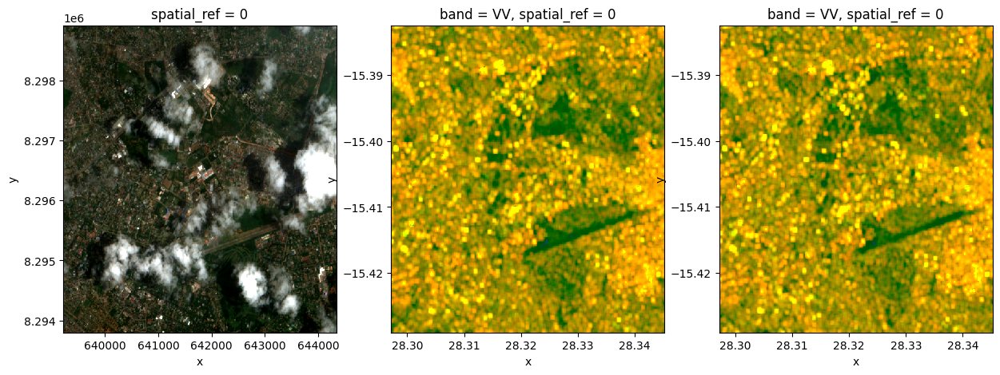

In [12]:
# let's plot the patches together
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# plot the s2image
s2.plot.imshow(ax=axs[0], rgb='band', robust=True)

# plot the s1images
for key in ['1', '2']:
    s1imgs[key].plot.imshow(ax=axs[int(key)], rgb='color_band')


# Global Coverage

Now that we've taken a look at one patch, let's see how they are spread over the globe. 
For that, we are going to load the json into a GeoDataFrame (geopandas).

In [13]:
# Convert the `geo` tag in shapely Polygons
geoms = {key: shape(item['geo']) for key, item in s2json.items()}

# create a GeoDataFrame with the patches and the geometries
gdf = gpd.GeoDataFrame({'patch': geoms.keys(), 'footprint': geoms.values()})

# create the centroid to be the geometry column of the DataFrame
gdf['center'] = gpd.GeoSeries(gdf['footprint']).centroid
gdf.set_geometry('center', inplace=True)

In [14]:
# Additionally, let's load the countries to serve as basemap
# The geojson for this and many other layers are freely available from `geojson.xyz` webseite.
globe = gpd.read_file('https://d2ad6b4ur7yvpq.cloudfront.net/naturalearth-3.3.0/ne_50m_admin_0_countries.geojson')

<Axes: >

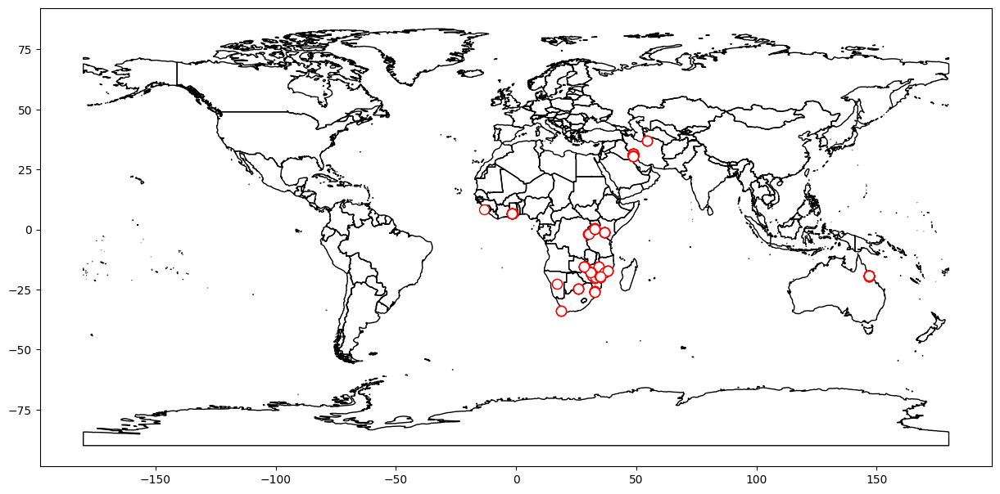

In [15]:
ax = globe.plot(facecolor='none', figsize=(15, 10))
gdf.plot(ax=ax, color='red', facecolor='white', markersize=75)

# Flood Event

To Finish this EDA, let's take a look at a flood event. For that, let's take a patch with that has flooded images.

## Helper function to extract images

In [16]:
def extract_imgs(data_item: dict) -> pd.DataFrame:
    """Extract all the images in a specific patch (location)"""
    
    # get attributes from the item
    folder = data_item['folder']
    count = data_item['count']
    
    if 'urls' in data_item:
        del data_item['urls']
    
    # create a dataframe with the images
    df = pd.DataFrame(data_item).T
    df = df.drop(index=['folder', 'count', 'geo'], columns=['type', 'coordinates'])
    
    # save attributes
    df['folder'] = folder
    df['count'] = count
    
    # at last, drop missing files
    return df.dropna()
    

def plot_s2patch(patch: str, s2data: pd.DataFrame, cols: int = 3):
    
    # get a df with the images to be plotted
    df = s2data.query(f'folder == "{patch}"').sort_values('date').reset_index(drop=True)
    n = len(df)
    
    # create a plotting area
    rows = n//cols + (1 if n%cols > 0 else 0)
    
    fig, axs = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
    axs = axs.reshape(-1)
    
    for i, row in df.iterrows(): 
        ax=axs[i]
        
        s2img = load_img (
            folder = root/row['folder'],
            filename=row['filename']
        ) / 1e4
        
        s2img.plot.imshow(rgb='band', vmin=0, vmax=0.3, ax=ax)
        
        title = '(flood)' if row['FLOODING'] else '(no flood)'
        title = row['date'] + ' ' + title
        ax.set_title(title)

        

def plot_s1patch(patch: str, s1data: pd.DataFrame, cols: int = 4):
    
    # get a df with the images to be plotted
    df = s1data.query(f'folder == "{patch}"').sort_values('date').reset_index(drop=True)
    n = len(df)
    
    # create a plotting area
    rows = n//cols + (1 if n%cols > 0 else 0)
    
    fig, axs = plt.subplots(rows, cols, figsize=(cols * 7, rows * 7))
    axs = axs.reshape(-1)
    
    for i, row in df.iterrows(): 
        ax=axs[i]

        s1img = load_img (
            folder = root/row['folder'],
            filename=row['filename'] + '_corrected',
            bands=['VV', 'VH']    
        )
        
        s1img.data = lee_filter(s1img, 7)
        s1img = false_color(s1img.sel(band='VV'), s1img.sel(band='VH'))
        
        s1img.plot.imshow(rgb='color_band', ax=ax)
        
        title = '(flood)' if row['FLOODING'] else '(no flood)'
        title = row['date'] + ' ' + title
        title = title + '\n' + row['orbit']
        ax.set_title(title)

## Load images list into dataframes

In [17]:
# Organize the data in DataFrames for the s2 and s1 images
s2data = pd.concat([extract_imgs(item) for item in s2json.values()], axis=0)
s1data = pd.concat([extract_imgs(item) for item in s1json.values()], axis=0)

s2patches = s2data.groupby('folder').max()
s1patches = s1data.groupby('folder').max()

patches = s2patches.join(s1patches, lsuffix='_S2', rsuffix='_S1')

In [18]:
patches.query('FLOODING_S2 == True')

,date_S2,FLOODING_S2,FULL-DATA-COVERAGE,filename_S2,count_S2,date_S1,FLOODING_S1,orbit,filename_S1,count_S1
folder,,,,,,,,,,
0,2019-04-21,True,True,S2_2019-04-21,9,2019-04-19,True,DESCENDING,S1B_IW_GRDH_1SDV_20190419T160654_20190419T1607...,20
0137,2019-04-09,True,True,S2_2019-04-09,6,2019-04-07,True,DESCENDING,S1B_IW_GRDH_1SDV_20190407T160813_20190407T1608...,12
0138,2019-04-09,True,True,S2_2019-04-09,6,2019-04-07,True,DESCENDING,S1B_IW_GRDH_1SDV_20190407T160748_20190407T1608...,10
0139,2019-04-09,True,True,S2_2019-04-09,6,2019-04-07,True,DESCENDING,S1B_IW_GRDH_1SDV_20190407T160748_20190407T1608...,10
0140,2019-04-21,True,True,S2_2019-04-21,9,2019-04-19,True,DESCENDING,S1B_IW_GRDH_1SDV_20190419T160654_20190419T1607...,28
...,...,...,...,...,...,...,...,...,...,...
61,2019-04-24,True,True,S2_2019-04-24,9,2019-04-17,True,DESCENDING,S1B_IW_GRDH_1SDV_20190417T162320_20190417T1623...,15
62,2019-04-23,True,True,S2_2019-04-23,9,2019-04-21,False,DESCENDING,S1B_IW_GRDH_1SDV_20190420T024612_20190420T0246...,17
63,2019-04-23,True,True,S2_2019-04-23,9,2019-04-20,False,DESCENDING,S1B_IW_GRDH_1SDV_20190420T024612_20190420T0246...,14


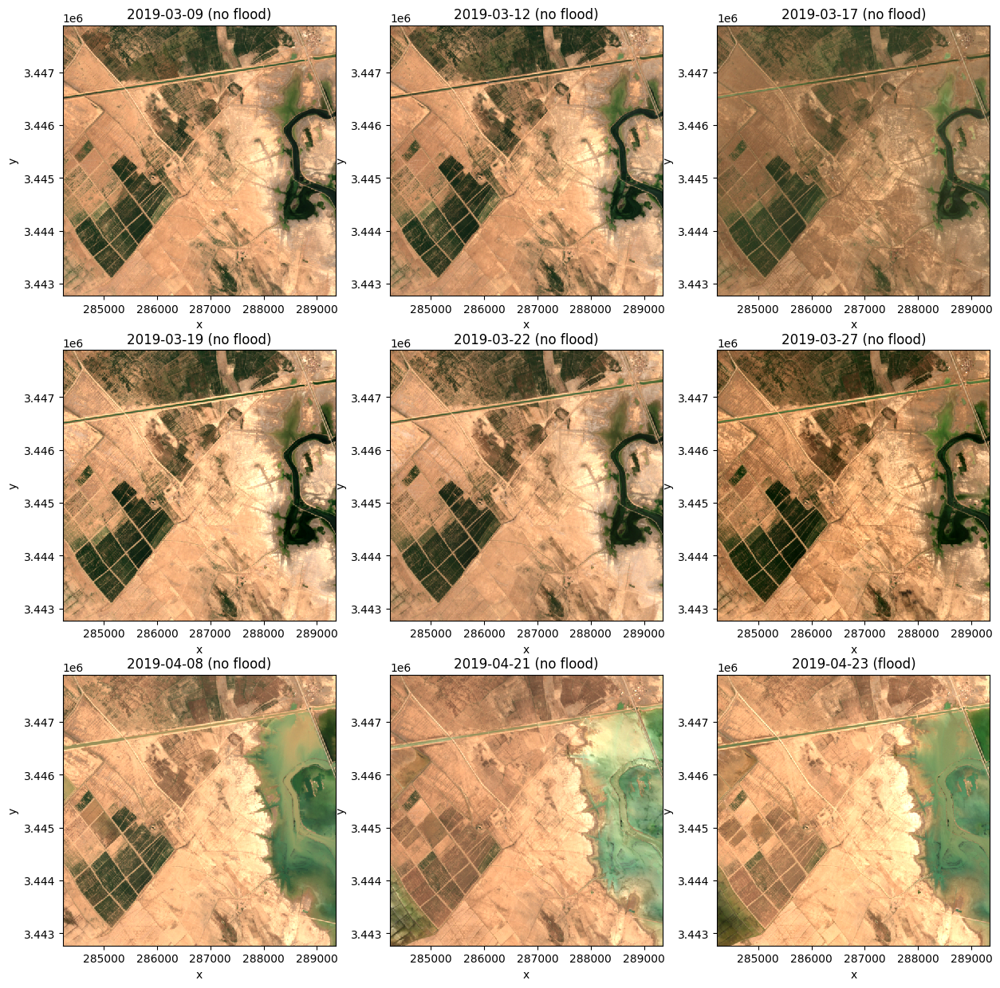

In [19]:
plot_s2patch('65', s2data)

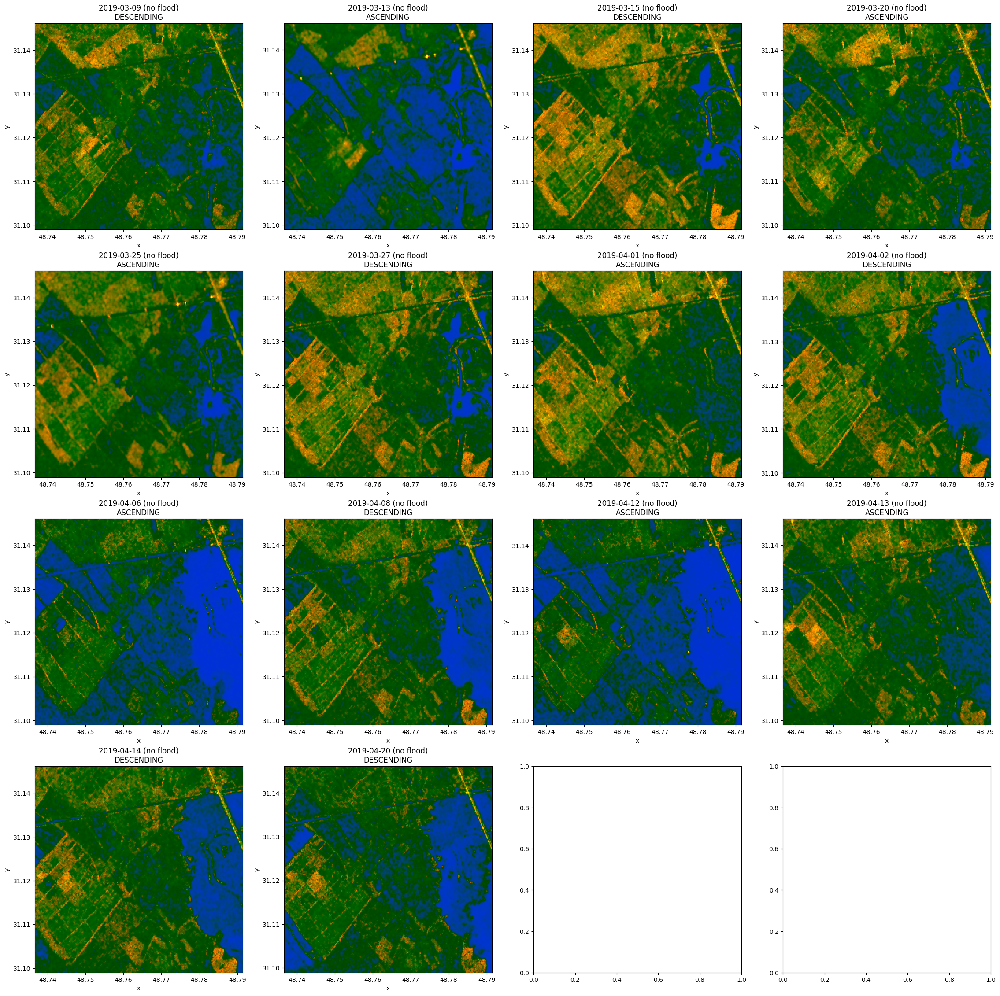

In [20]:
plot_s1patch('65', s1data)

I doubled checked this dataset and the code many times. This location (65) seems to have an issue with the labels. 

In [21]:
s1data.to_csv('s1data.csv')
s2data.to_csv('s2data.csv')

In [22]:
patches.to_csv('patches.csv')